In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

,code_length,users,condition,bit_errors,bits_tested,BER,processing_gain_linear,processing_gain_dB
0,8,2,walsh_sync,0,40000,0.000000,8,9.0309
1,8,2,random_sync,276,40000,0.006900,8,9.0309
2,8,2,walsh_sync_10x,0,40000,0.000000,8,9.0309
3,8,2,walsh_async,4,40000,0.000100,8,9.0309
4,8,2,walsh_async_10x,904,40000,0.022600,8,9.0309
5,8,4,walsh_sync,1,40000,0.000025,8,9.0309
6,8,4,random_sync,1999,40000,0.049975,8,9.0309
7,8,4,walsh_sync_10x,1,40000,0.000025,8,9.0309
8,8,4,walsh_async,164,40000,0.004100,8,9.0309
9,8,4,walsh_async_10x,1450,40000,0.036250,8,9.0309


,L,max_abs_walsh_cross_correlation,rms_off_diagonal
0,8,1.110223e-16,4.113917e-17
1,16,0.000000e+00,0.000000e+00
2,64,0.000000e+00,0.000000e+00


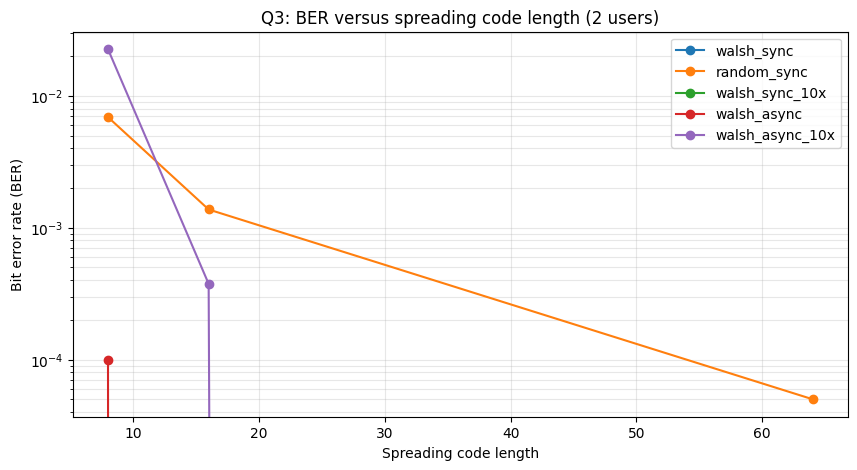

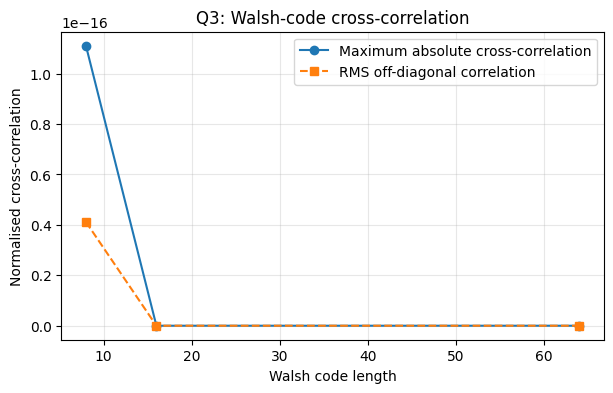

In [3]:
def hadamard(n):
    H = np.array([[1.0]])
    while H.shape[0] < n:
        H = np.block([[H,H],[H,-H]])
    return H

def q3_trial(L, K, condition, seed, nbits=1000, ebn0_db=10):
    rng = np.random.default_rng(seed)
    H = hadamard(L)
    codes = H[:K].copy()
    if condition == "random_sync":
        codes = rng.choice([-1.0,1.0], size=(K,L))
    # Equal power except near-far condition: user 1 has 10x power.
    amp = np.ones(K)
    if condition == "walsh_sync_10x" and K > 1:
        amp[1] = np.sqrt(10)
    bits = rng.choice([-1.0,1.0], size=(K,nbits))
    chips = (bits[:,:,None] * codes[:,None,:]).reshape(K,-1) * amp[:,None]
    # Optional asynchronous integer-chip offset for each interferer.
    if condition in ("walsh_async","walsh_async_10x"):
        rx = np.zeros(chips.shape[1] + L)
        for k in range(K):
            offset = 0 if k == 0 else int(rng.integers(1,L))
            scale = np.sqrt(10) if (condition=="walsh_async_10x" and k==1) else 1.0
            rx[offset:offset+chips.shape[1]] += chips[k] * scale
    else:
        rx = chips.sum(axis=0)
    ebn0 = 10**(ebn0_db/10)
    sigma = np.sqrt(L/(2*ebn0))
    rx += rng.normal(0,sigma,size=rx.size)
    # Reference user aligned despreading.
    usable = rx[:nbits*L].reshape(nbits,L)
    decision = np.sign((usable @ codes[0])/L)
    errors = int(np.sum(decision != bits[0]))
    return errors, errors/nbits

q3_rows=[]
for L in (8,16,64):
    for K in sorted(set([2, max(2,L//4), max(2,L//2), L])):
        for cond in ("walsh_sync","random_sync","walsh_sync_10x","walsh_async","walsh_async_10x"):
            errs=[]
            for rep in range(40):
                e,_=q3_trial(L,K,cond,3000+L*100+K*10+rep)
                errs.append(e)
            total=sum(errs); bits=40*1000
            q3_rows.append([L,K,cond,total,bits,total/bits,L,10*np.log10(L)])
q3=pd.DataFrame(q3_rows,columns=["code_length","users","condition","bit_errors","bits_tested","BER","processing_gain_linear","processing_gain_dB"])
display(q3.round(6))
q3.to_csv("q3_ber.csv",index=False)

# Correlation evidence for synchronous codes.
corr_rows=[]
for L in (8,16,64):
    H=hadamard(L)
    C=H/np.sqrt(L)
    off=C@C.T-np.eye(L)
    corr_rows.append([L,float(np.max(np.abs(off))),float(np.sqrt(np.mean(off**2)))])
q3_corr=pd.DataFrame(corr_rows,columns=["L","max_abs_walsh_cross_correlation","rms_off_diagonal"])
display(q3_corr)
q3_corr.to_csv("q3_correlation.csv",index=False)

# Visualisation 1: BER versus processing gain/code length
plt.figure(figsize=(10,5))
for cond in ("walsh_sync", "random_sync", "walsh_sync_10x", "walsh_async", "walsh_async_10x"):
    sub = q3[(q3["condition"] == cond) & (q3["users"] == 2)].sort_values("code_length")
    plt.semilogy(sub["code_length"], sub["BER"], marker="o", label=cond)
plt.xlabel("Spreading code length")
plt.ylabel("Bit error rate (BER)")
plt.title("Q3: BER versus spreading code length (2 users)")
plt.grid(True, which="both", alpha=.3)
plt.legend()
plt.show()

# Visualisation 2: cross-correlation of synchronous Walsh codes
plt.figure(figsize=(7,4))
plt.plot(q3_corr["L"], q3_corr["max_abs_walsh_cross_correlation"], "o-", label="Maximum absolute cross-correlation")
plt.plot(q3_corr["L"], q3_corr["rms_off_diagonal"], "s--", label="RMS off-diagonal correlation")
plt.xlabel("Walsh code length")
plt.ylabel("Normalised cross-correlation")
plt.title("Q3: Walsh-code cross-correlation")
plt.grid(True, alpha=.3)
plt.legend()
plt.show()
